# F1 Race Position Predictor 🏎️

**Prever, *antes* de uma corrida de Formula 1, em que faixa de resultado cada piloto vai terminar.**

Em vez de tentar adivinhar a posicao exata (P1, P2, P3, ...), o problema e tratado como uma
**classificacao em 3 classes**:

| Classe | Significado | Posicao final |
|---|---|---|
| **Podium** | subiu ao podio | P1 a P3 |
| **Points** | pontuou | P4 a P10 |
| **Out of Points** | fora dos pontos (ou abandonou) | P11 ou pior |

**Por que nao prever a posicao exata?** Uma corrida tem muito acaso: safety car, chuva, batidas,
falhas mecanicas, estrategia de pit stop. Prever "P7 exatamente" e quase impossivel e o modelo
ficaria com uma acuracia baixissima. Agrupando em 3 faixas, capturamos o que realmente importa
("esse piloto tende a pontuar?") e o problema fica aprendivel.

---

### Roteiro do notebook
1. Imports e configuracao
2. Carga dos dados (7 CSVs do Kaggle)
3. Join das tabelas
4. Definicao do alvo e tratamento de abandonos (DNF)
5. Recorte da era moderna (2000+)
6. Limpeza de dados e valores nulos
7. EDA rapida (graficos exploratorios)
8. Engenharia de atributos (features)
9. Split estratificado 80/20
10. Modelo principal: Random Forest
11. Baseline: Regressao Logistica
12. Avaliacao (acuracia, matriz de confusao, classification report, feature importance)
13. Salvando o modelo com pickle
14. Conclusoes

## 1. Imports e configuracao

Bibliotecas usadas:
- **pandas / numpy** - manipulacao de tabelas e calculo numerico.
- **matplotlib** - graficos.
- **scikit-learn** - `LabelEncoder` (codificar texto em numero), `train_test_split` (dividir treino/teste),
  `RandomForestClassifier` (modelo principal), `LogisticRegression` (baseline), metricas de avaliacao.
- **pickle** - salvar o modelo treinado em disco.

`RANDOM_STATE = 42` fixa a aleatoriedade (split e florestas) para o notebook ser **reprodutivel**:
rodar de novo da o mesmo resultado.

In [22]:
import os
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

RANDOM_STATE = 42
DATA_DIR = "data"          # pasta com os CSVs do Kaggle
NA_TOKENS = ["\\N"]        # o dataset (herdado da API Ergast) usa "\\N" para nulo
LABELS = ["Podium", "Points", "Out of Points"]   # ordem fixa p/ graficos e relatorios

## 2. Carga dos dados

Dataset: **Formula 1 World Championship (1950-2020)** do Kaggle
(<https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020>) -
um espelho da antiga API Ergast, que foi **descontinuada**. Apesar do nome, a versao atual
do dataset vai ate **2024**.

Baixe o dataset e coloque os arquivos `.csv` numa pasta `data/` ao lado deste notebook.
As 7 tabelas que vamos usar:

| Arquivo | O que tem | Chave(s) |
|---|---|---|
| `races.csv` | cada GP: ano, round (etapa), circuito, data | `raceId`, `circuitId` |
| `results.csv` | resultado de cada piloto em cada GP: grid, posicao final, pontos, status | `raceId`, `driverId`, `constructorId` |
| `qualifying.csv` | classificacao do sabado: posicao e tempos Q1/Q2/Q3 | `raceId`, `driverId` |
| `drivers.csv` | pilotos: nome, nacionalidade, data de nascimento | `driverId` |
| `constructors.csv` | equipes (construtores): nome, nacionalidade | `constructorId` |
| `circuits.csv` | pistas: nome, pais, localizacao | `circuitId` |
| `status.csv` | texto do status final ("Finished", "Accident", "Engine", ...) | `statusId` |

> Alternativa de download automatico (precisa de conta Kaggle configurada):
> ```python
> # import kagglehub, shutil, glob
> # src = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")
> # os.makedirs("data", exist_ok=True)
> # for f in glob.glob(os.path.join(src, "*.csv")): shutil.copy(f, "data/")
> ```

In [23]:
def load_csv(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Nao encontrei '{path}'. Baixe o dataset 'Formula 1 World Championship "
            f"(1950-2020)' do Kaggle e coloque os CSVs na pasta '{DATA_DIR}/'."
        )
    return pd.read_csv(path, na_values=NA_TOKENS)

races        = load_csv("races.csv")
results      = load_csv("results.csv")
qualifying   = load_csv("qualifying.csv")
drivers      = load_csv("drivers.csv")
constructors = load_csv("constructors.csv")
circuits     = load_csv("circuits.csv")
status       = load_csv("status.csv")

for nome, tab in [("races", races), ("results", results), ("qualifying", qualifying),
                  ("drivers", drivers), ("constructors", constructors),
                  ("circuits", circuits), ("status", status)]:
    print(f"{nome:12s} {tab.shape}")

races        (1125, 18)
results      (26759, 18)
qualifying   (10494, 9)
drivers      (861, 9)
constructors (212, 5)
circuits     (77, 9)
status       (139, 2)


In [24]:
# espiada rapida na tabela central
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


## 3. Join das tabelas

`results.csv` e a tabela central (uma linha = um piloto numa corrida). Vamos **anexar** a ela as
informacoes das outras tabelas usando as chaves:

- `raceId`  -> traz `year`, `round`, `circuitId`, data (de `races`)
- `driverId` -> traz `driverRef`, nacionalidade, nascimento (de `drivers`)
- `constructorId` -> traz o nome da equipe (de `constructors`)
- `circuitId` -> traz o `circuitRef` e o pais (de `circuits`)
- `statusId` -> traz o texto do status final (de `status`)

Usamos sempre `how="left"`: manter todas as linhas de `results` e completar com o que casar.
`qualifying` fica para depois (secao 8), porque precisa de tratamento dos tempos.

In [25]:
df = (
    results
    .merge(races[["raceId", "year", "round", "circuitId", "name", "date"]],
           on="raceId", how="left")
    .merge(drivers[["driverId", "driverRef", "nationality", "dob"]],
           on="driverId", how="left")
    .merge(constructors[["constructorId", "constructorRef", "name"]]
           .rename(columns={"name": "constructor_name", "constructorRef": "constructor_ref"}),
           on="constructorId", how="left")
    .merge(circuits[["circuitId", "circuitRef", "country"]],
           on="circuitId", how="left")
    .merge(status[["statusId", "status"]], on="statusId", how="left")
    .rename(columns={"name": "race_name", "nationality": "driver_nationality"})
)

print("shape apos os joins:", df.shape)
df[["year", "round", "race_name", "driverRef", "constructor_name",
    "grid", "positionOrder", "status"]].head()

shape apos os joins: (26759, 31)


,year,round,race_name,driverRef,constructor_name,grid,positionOrder,status
0,2008,1,Australian Grand Prix,hamilton,McLaren,1,1,Finished
1,2008,1,Australian Grand Prix,heidfeld,BMW Sauber,5,2,Finished
2,2008,1,Australian Grand Prix,rosberg,Williams,7,3,Finished
3,2008,1,Australian Grand Prix,alonso,Renault,11,4,Finished
4,2008,1,Australian Grand Prix,kovalainen,McLaren,3,5,Finished


## 4. Definicao do alvo (target) e tratamento dos abandonos (DNF)

### 4.1 Como transformar "posicao final" em 3 classes

A coluna **`positionOrder`** e a ordem de classificacao oficial da corrida (1, 2, 3, ...). Ela esta
**sempre preenchida** - diferente de `position`, que fica nula para quem nao foi classificado.
Regra:

- `positionOrder <= 3`  -> **Podium**
- `4 <= positionOrder <= 10` -> **Points**
- `positionOrder >= 11` -> **Out of Points**

### 4.2 O que fazer com os DNFs (abandonos)?

Cerca de **23% das linhas na era moderna sao abandonos** (batida, motor, cambio, etc.). Um piloto
que quebra na volta 5 nao "terminou em P18" da mesma forma que alguem que cruzou a linha em P18.

Duas abordagens possiveis:

1. **Remover os DNFs** e treinar so com quem terminou. Simples, mas joga fora 1/4 dos dados e
   *enviesa* o alvo: o modelo passa a assumir que todo mundo termina, e a classe "Out of Points"
   fica artificialmente rara.
2. **Manter os DNFs**, usando a classificacao oficial (`positionOrder`) como resultado. Um abandono
   quase sempre cai em "Out of Points" - que e, de fato, o resultado da corrida para aquele piloto.

**Decisao adotada: opcao 2 (manter os DNFs).** O objetivo do modelo e prever o *resultado da corrida*,
e um abandono e um resultado ruim real. Carros frageis / equipes pequenas abandonam mais, e isso e
justamente um sinal que o modelo deve aprender. Criamos tambem uma flag `finished` para conseguir
medir e comentar esse efeito na EDA e na avaliacao.

> Consequencia honesta dessa escolha: parte dos erros de "Out of Points" vem de puro azar
> (um lider que quebra). Nenhum modelo pre-corrida acerta isso - voltamos a esse ponto nas conclusoes.

In [26]:
df["positionOrder"] = pd.to_numeric(df["positionOrder"], errors="coerce")

def to_class(p):
    if p <= 3:
        return "Podium"
    if p <= 10:
        return "Points"
    return "Out of Points"

df["target"] = df["positionOrder"].apply(to_class)

# flag de quem completou a corrida (terminou ou levou volta(s), mas foi classificado)
df["finished"] = (df["status"].eq("Finished")
                  | df["status"].str.contains("Lap", na=False))

print(df["target"].value_counts(), "\n")
print("status mais comuns:\n", df["status"].value_counts().head(8))

target
Out of Points    15438
Points            7924
Podium            3397
Name: count, dtype: int64 

status mais comuns:
 status
Finished           7674
+1 Lap             4037
Engine             2026
+2 Laps            1613
Accident           1062
Did not qualify    1025
Collision           854
Gearbox             810
Name: count, dtype: int64


## 5. Recorte da era moderna (2000+)

A F1 mudou muito ao longo de 70 anos: numero de carros, regras de pontuacao, confiabilidade,
formato da classificacao. Misturar 1955 com 2020 introduz ruido e "conceitos" diferentes.

Filtramos **de 2000 ate o ano mais recente do dataset (2024)** - uma janela em que o esporte
e razoavelmente comparavel de um ano para o outro.

In [27]:
ANO_MIN = 2000
df = df[(df["year"] >= ANO_MIN) & (df["year"] <= df["year"].max())].copy()

print("linhas:", len(df))
print("periodo:", df["year"].min(), "-", df["year"].max())
print("corridas:", df["raceId"].nunique())
print("taxa de abandono (DNF):", round(1 - df["finished"].mean(), 3))

linhas: 10079
periodo: 2000 - 2024
corridas: 479
taxa de abandono (DNF): 0.231


## 6. Limpeza de dados e valores nulos

**`grid` (posicao de largada).** No dataset, largada do *pit lane* ou sem tempo valido aparece como
`grid = 0`. Isso nao e "primeira posicao"! Trocamos `0` por nulo e depois preenchemos com **20**
(fundo do grid) - que e o significado pratico de largar do pit lane.

**`date`.** Convertemos para data de verdade e **ordenamos o dataframe cronologicamente**. Isso e
essencial: varias features (forma recente, forca da equipe) sao "janelas do passado" e so fazem
sentido com as linhas em ordem de tempo.

In [28]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["grid"] = pd.to_numeric(df["grid"], errors="coerce")

GRID_BACK = 20
n_pit = int((df["grid"] == 0).sum())
df.loc[df["grid"] == 0, "grid"] = np.nan
df["grid"] = df["grid"].fillna(GRID_BACK)
print(f"{n_pit} largadas do pit lane / sem grid -> tratadas como P{GRID_BACK}")

df = df.sort_values(["date", "raceId", "positionOrder"]).reset_index(drop=True)

# panorama de nulos nas colunas que vao entrar no modelo
df[["grid", "positionOrder", "year", "round", "driver_nationality",
    "constructor_name", "circuitRef"]].isna().sum()

93 largadas do pit lane / sem grid -> tratadas como P20


grid                  0
positionOrder         0
year                  0
round                 0
driver_nationality    0
constructor_name      0
circuitRef            0
dtype: int64

## 7. EDA rapida

Quatro perguntas antes de modelar:

1. As classes estao balanceadas?
2. A posicao de largada realmente prediz o resultado?
3. Quais equipes dominam o podio nesse periodo?
4. Quanto de "azar" (abandono) existe por temporada?

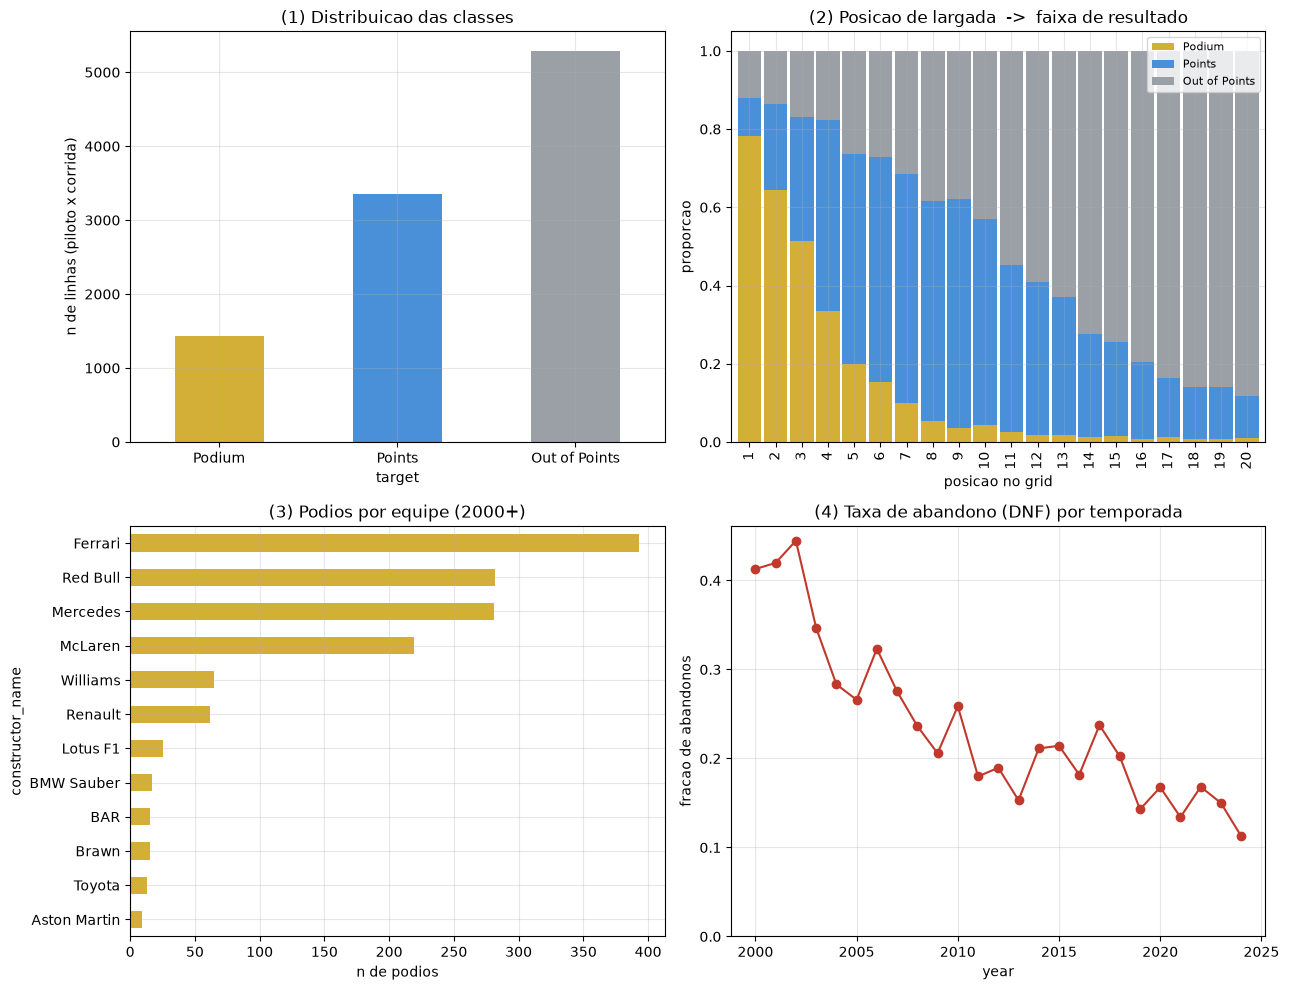

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# (1) distribuicao das classes
df["target"].value_counts().reindex(LABELS).plot(
    kind="bar", ax=axes[0, 0], color=["#d4af37", "#4a90d9", "#9aa0a6"])
axes[0, 0].set_title("(1) Distribuicao das classes")
axes[0, 0].set_ylabel("n de linhas (piloto x corrida)")
axes[0, 0].tick_params(axis="x", rotation=0)

# (2) largada x resultado: proporcao de cada classe por posicao de grid
g = df.copy()
g["grid_bin"] = g["grid"].clip(upper=20).astype(int)
tab = pd.crosstab(g["grid_bin"], g["target"], normalize="index")[LABELS]
tab.plot(kind="bar", stacked=True, ax=axes[0, 1],
         color=["#d4af37", "#4a90d9", "#9aa0a6"], width=0.9)
axes[0, 1].set_title("(2) Posicao de largada  ->  faixa de resultado")
axes[0, 1].set_xlabel("posicao no grid"); axes[0, 1].set_ylabel("proporcao")
axes[0, 1].legend(title="", fontsize=8)

# (3) podios por equipe (top 12)
podios = (df[df["target"] == "Podium"]
          .groupby("constructor_name").size().sort_values().tail(12))
podios.plot(kind="barh", ax=axes[1, 0], color="#d4af37")
axes[1, 0].set_title("(3) Podios por equipe (2000+)")
axes[1, 0].set_xlabel("n de podios")

# (4) taxa de abandono por ano
dnf_ano = 1 - df.groupby("year")["finished"].mean()
dnf_ano.plot(marker="o", ax=axes[1, 1], color="#c0392b")
axes[1, 1].set_title("(4) Taxa de abandono (DNF) por temporada")
axes[1, 1].set_ylabel("fracao de abandonos"); axes[1, 1].set_ylim(0, None)

plt.tight_layout()
plt.show()

**Leitura dos graficos:**

1. **Classes desbalanceadas.** "Out of Points" e ~52% das linhas, "Points" ~33%, "Podium" so ~14%
   (sao 3 vagas de podio para ~20 carros). Isso vai exigir `class_weight="balanced"` no modelo -
   senao ele aprende a quase nunca dizer "Podium".
2. **Largar na frente e quase tudo.** Quem larga no top 3 sobe ao podio na maioria das vezes; a
   partir de ~P8 a esmagadora maioria termina fora dos pontos. `grid` vai ser uma feature muito forte.
3. **Concentracao de podios** em Ferrari, Red Bull, Mercedes, McLaren - historico de equipe importa.
4. **Confiabilidade melhorou** muito: a taxa de abandono cai de ~30-40% no comeco dos anos 2000 para
   ~15% nos anos recentes. Por isso incluimos `year` como feature.

## 8. Engenharia de atributos (features)

A ideia central: **so podemos usar informacao disponivel ANTES da largada.** Nada de "numero de
voltas completadas" ou "pontos ganhos nessa corrida" - isso seria *data leakage* (o modelo
"espiando" a resposta).

Toda feature de historico e calculada com `groupby(...).shift()` **antes** da janela movel/expansiva,
para que a linha da corrida atual nunca entre no proprio calculo.

| Feature | O que e | Por que ajuda |
|---|---|---|
| `grid` | posicao de largada | melhor preditor isolado: ultrapassar na F1 e dificil |
| `quali_position` | posicao no grid de classificacao (sabado) | ritmo puro do conjunto carro+piloto, sem punicoes de grid |
| `quali_time_gap` | diferenca (s) do melhor tempo de quali do piloto para a pole | mede *quao rapido*, nao so a ordem (pole por 0,01s != pole por 0,8s) |
| `recent_form` | media da `positionOrder` nas ultimas 3 corridas do piloto | momento atual: lesao, carro evoluiu, adaptacao |
| `driver_experience` | n de corridas ja disputadas pelo piloto | novato tende a oscilar e errar mais |
| `constructor_form` | media de pontos da equipe nas ultimas 5 corridas | o carro do momento (upgrades, regulamento) |
| `constructor_season_pts` | media de pontos da equipe na temporada ate aqui | forca estrutural da equipe naquele ano |
| `year` | temporada | confiabilidade e ordem competitiva mudam com o tempo |
| `round` | numero da etapa na temporada | inicio de ano tem mais incerteza; features de forma sao mais rasas |
| `circuit_enc` | circuito (codificado) | Monaco (quase impossivel ultrapassar) != Monza |
| `driver_enc` | piloto (codificado) | habilidade individual que as outras features nao capturam |
| `constructor_enc` | equipe (codificada) | idem, no nivel de equipe |
| `nationality_enc` | nacionalidade do piloto (codificada) | proxy fraco de escola de formacao / pipeline de talento |

### 8.1 Qualifying: posicao e tempo

In [30]:
def time_to_seconds(t):
    # '1:23.456' -> 83.456 segundos. Nulo/invalido -> NaN.
    if pd.isna(t):
        return np.nan
    try:
        minutes, seconds = str(t).split(":")
        return int(minutes) * 60 + float(seconds)
    except ValueError:
        return np.nan

q = qualifying.copy()
for c in ["q1", "q2", "q3"]:
    q[c] = q[c].map(time_to_seconds)

# melhor tempo do piloto no fim de semana = menor entre Q1, Q2 e Q3
q["quali_time"] = q[["q1", "q2", "q3"]].min(axis=1)
q = q.rename(columns={"position": "quali_position"})[
    ["raceId", "driverId", "quali_position", "quali_time"]]

df = df.merge(q, on=["raceId", "driverId"], how="left")

# gap para a pole, calculado DENTRO de cada corrida
df["quali_time_gap"] = (df["quali_time"]
                        - df.groupby("raceId")["quali_time"].transform("min"))

# fallbacks para quando nao ha dado de quali (quali antiga sem Q2/Q3, DNS, etc.)
df["quali_position"] = df["quali_position"].fillna(df["grid"])
df["quali_time_gap"] = df["quali_time_gap"].fillna(
    df.groupby("raceId")["quali_time_gap"].transform("median"))
df["quali_time_gap"] = df["quali_time_gap"].fillna(df["quali_time_gap"].median())

df[["driverRef", "grid", "quali_position", "quali_time_gap"]].head()

,driverRef,grid,quali_position,quali_time_gap
0,michael_schumacher,3.0,3.0,0.519
1,barrichello,4.0,4.0,0.546
2,ralf_schumacher,11.0,11.0,1.664
3,villeneuve,8.0,8.0,1.412
4,fisichella,9.0,9.0,1.436


### 8.2 Forma recente do piloto e experiencia

`recent_form` = media da posicao de chegada nas **ultimas 3 corridas** daquele piloto.
`.shift()` garante que a corrida atual nao entra na conta. `min_periods=1` deixa calcular
mesmo com so 1-2 corridas anteriores. Quem nao tem historico nenhum (estreia absoluta no
periodo) recebe a **mediana** como chute neutro.

In [31]:
N_FORM = 3
df["recent_form"] = (
    df.groupby("driverId")["positionOrder"]
      .transform(lambda s: s.shift().rolling(N_FORM, min_periods=1).mean())
)
df["recent_form"] = df["recent_form"].fillna(df["positionOrder"].median())

df["driver_experience"] = df.groupby("driverId").cumcount()

df[["driverRef", "year", "round", "positionOrder", "recent_form", "driver_experience"]].head(10)

,driverRef,year,round,positionOrder,recent_form,driver_experience
0,michael_schumacher,2000,1,1,11.0,0
1,barrichello,2000,1,2,11.0,0
2,ralf_schumacher,2000,1,3,11.0,0
3,villeneuve,2000,1,4,11.0,0
4,fisichella,2000,1,5,11.0,0
5,zonta,2000,1,6,11.0,0
6,wurz,2000,1,7,11.0,0
7,gene,2000,1,8,11.0,0
8,heidfeld,2000,1,9,11.0,0
9,salo,2000,1,10,11.0,0


### 8.3 Forca da equipe (construtor)

Duas visoes complementares:
- **`constructor_form`** - media de pontos da equipe (somando os 2 carros) nas ultimas 5 corridas.
  Pega o "carro do momento".
- **`constructor_season_pts`** - media de pontos da equipe na temporada ate a etapa anterior.
  Pega a forca estrutural no ano.

Calculamos primeiro os pontos da equipe **por corrida** (soma dos carros), ordenamos por data e
so entao aplicamos as janelas com `.shift()`. Equipe/etapa sem historico -> `0` (equipe fraca /
estreante), que e um chute conservador.

In [32]:
cons = (
    df.groupby(["constructorId", "raceId"], as_index=False)
      .agg(cons_points=("points", "sum"),
           date=("date", "first"),
           year=("year", "first"))
      .sort_values("date")
)

cons["constructor_form"] = (
    cons.groupby("constructorId")["cons_points"]
        .transform(lambda s: s.shift().rolling(5, min_periods=1).mean())
)
cons["constructor_season_pts"] = (
    cons.groupby(["constructorId", "year"])["cons_points"]
        .transform(lambda s: s.shift().expanding().mean())
)

df = df.merge(
    cons[["constructorId", "raceId", "constructor_form", "constructor_season_pts"]],
    on=["constructorId", "raceId"], how="left"
)
df["constructor_form"] = df["constructor_form"].fillna(0)
df["constructor_season_pts"] = df["constructor_season_pts"].fillna(0)

df[["constructor_name", "year", "round", "constructor_form", "constructor_season_pts"]].head()

,constructor_name,year,round,constructor_form,constructor_season_pts
0,Ferrari,2000,1,0.0,0.0
1,Ferrari,2000,1,0.0,0.0
2,Williams,2000,1,0.0,0.0
3,BAR,2000,1,0.0,0.0
4,Benetton,2000,1,0.0,0.0


### 8.4 Label Encoding das colunas categoricas

Modelos de scikit-learn so recebem numeros. `LabelEncoder` mapeia cada categoria de texto para um
inteiro (`albert_park -> 0`, `bahrain -> 1`, ...). Guardamos os encoders num dicionario para
reaproveitar depois (ao salvar o modelo / no app).

> Nota: para arvores (Random Forest) o Label Encoding funciona bem. Para modelos lineares como a
> Regressao Logistica ele nao e ideal (cria uma ordem artificial entre categorias) - por isso o
> baseline linear e so referencia, nao o modelo final.

In [33]:
cat_map = {
    "driverRef":          "driver_enc",
    "constructor_ref":    "constructor_enc",
    "circuitRef":         "circuit_enc",
    "driver_nationality": "nationality_enc",
}

encoders = {}
for src, new in cat_map.items():
    le = LabelEncoder()
    df[new] = le.fit_transform(df[src].astype(str))
    encoders[src] = le
    print(f"{src:20s} -> {new:16s} ({len(le.classes_)} categorias)")

driverRef            -> driver_enc       (126 categorias)
constructor_ref      -> constructor_enc  (38 categorias)
circuitRef           -> circuit_enc      (38 categorias)
driver_nationality   -> nationality_enc  (35 categorias)


### 8.5 Matriz final de modelagem

In [34]:
FEATURES = [
    "grid", "quali_position", "quali_time_gap",
    "recent_form", "driver_experience",
    "constructor_form", "constructor_season_pts",
    "year", "round",
    "circuit_enc", "driver_enc", "constructor_enc", "nationality_enc",
]
TARGET = "target"

model_df = df.dropna(subset=["positionOrder"]).copy()
X = model_df[FEATURES]
y = model_df[TARGET]

print("X:", X.shape, "| nulos em X:", int(X.isna().sum().sum()))
print("\nproporcao das classes:")
print(y.value_counts(normalize=True).round(3))
X.describe().T[["mean", "std", "min", "max"]]

X: (10079, 13) | nulos em X: 0

proporcao das classes:
target
Out of Points    0.525
Points           0.333
Podium           0.143
Name: proportion, dtype: float64


,mean,std,min,max
grid,11.081159,6.157759,1.0,24.000
quali_position,11.067963,6.151737,1.0,24.000
quali_time_gap,1.913524,2.204123,0.0,40.245
recent_form,11.014783,4.733567,1.0,24.000
driver_experience,87.371465,80.278444,0.0,403.000
constructor_form,7.297553,9.462447,0.0,44.400
constructor_season_pts,6.963728,9.412359,0.0,44.000
year,2012.459768,7.165228,2000.0,2024.000
round,10.154678,5.696967,1.0,24.000
circuit_enc,17.950293,11.124876,0.0,37.000


## 9. Split estratificado 80/20

`train_test_split` com `stratify=y` divide os dados mantendo a **mesma proporcao das 3 classes**
em treino e teste. Sem isso, o acaso poderia colocar poucos "Podium" no teste e a avaliacao
ficaria instavel.

> Observacao (bom ponto de entrevista): um split *temporal* (treinar ate 2021, testar 2022-2024)
> seria mais realista para producao, porque em producao voce sempre preve o futuro. Aqui seguimos
> o split estratificado aleatorio pedido na especificacao; o `cross_val_score` mais adiante ajuda
> a checar estabilidade.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("treino:", X_train.shape, "| teste:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3).to_dict())
print(y_test.value_counts(normalize=True).round(3).to_dict())

treino: (8063, 13) | teste: (2016, 13)
{'Out of Points': 0.525, 'Points': 0.333, 'Podium': 0.143}
{'Out of Points': 0.525, 'Points': 0.333, 'Podium': 0.142}


## 10. Modelo principal: Random Forest

**O que e.** Uma "floresta" de varias arvores de decisao. Cada arvore ve uma amostra aleatoria das
linhas e, em cada no, um subconjunto aleatorio das features. A previsao final e o **voto da maioria**
das arvores. Essa aleatoriedade faz as arvores errarem de formas diferentes, e a media dos erros
sai menor - o modelo generaliza melhor do que uma arvore sozinha (que decoraria o treino).

**Por que aqui.** Captura relacoes nao lineares e interacoes entre features automaticamente
(ex.: "largar em P2 *em Monaco*" vale mais que "largar em P2" em geral), aceita features em escalas
diferentes sem normalizar, e entrega `feature_importances_` de graca.

**Parametros:**
- `n_estimators=200` - 200 arvores. Mais arvores = mais estavel, com custo de tempo.
- `max_depth=12` - limita a profundidade de cada arvore. Freia o overfitting.
- `class_weight="balanced"` - **da mais peso as classes raras** ("Podium") na hora de treinar,
  compensando o desbalanceamento visto na EDA.
- `random_state=42`, `n_jobs=-1` - reprodutibilidade e uso de todos os nucleos.

In [36]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print(f"Random Forest - acuracia no teste: {rf_acc:.3f}")

cv = cross_val_score(rf, X, y, cv=5, scoring="accuracy")
print(f"Acuracia em validacao cruzada (5 folds): {cv.mean():.3f} +/- {cv.std():.3f}")

Random Forest - acuracia no teste: 0.679
Acuracia em validacao cruzada (5 folds): 0.659 +/- 0.035


## 11. Baseline: Regressao Logistica

Antes de comemorar o resultado do Random Forest, precisamos de um **ponto de comparacao**. A
Regressao Logistica e um modelo linear simples: aprende um peso para cada feature e combina tudo
numa soma ponderada, transformada em probabilidade de cada classe.

Colocamos um `StandardScaler` antes (modelos lineares sao sensiveis a escala) e usamos o mesmo
`class_weight="balanced"`. Se o Random Forest nao superar (ou pelo menos empatar com) esse baseline,
a complexidade extra nao se justifica.

In [37]:
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced"),
)
logreg.fit(X_train, y_train)

lr_pred = logreg.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred)

print(f"Regressao Logistica (baseline) - acuracia: {lr_acc:.3f}")
print(f"Random Forest                  - acuracia: {rf_acc:.3f}")
print(f"diferenca: {rf_acc - lr_acc:+.3f}")

Regressao Logistica (baseline) - acuracia: 0.669
Random Forest                  - acuracia: 0.679
diferenca: +0.009


**Comentario.** Os dois modelos ficam na casa dos **~67-68%**. O sinal dominante do problema
(grid + forca da equipe + forma recente) e quase linear - "quanto mais na frente voce larga num
carro melhor, melhor voce termina" -, entao ate um modelo simples ja chega perto. O Random Forest
leva uma **vantagem pequena** porque captura as interacoes (circuito x grid, piloto x equipe) e
lida melhor com as categorias codificadas. Ele fica como modelo final por essa margem + a
interpretabilidade via feature importance; a diferenca modesta e, por si so, uma conclusao
interessante sobre o problema.

## 12. Avaliacao detalhada

- **Matriz de confusao** - onde o modelo confunde as classes.
- **Classification report** - precision / recall / f1 por classe.
- **Feature importance** - o que a floresta mais usa para decidir.

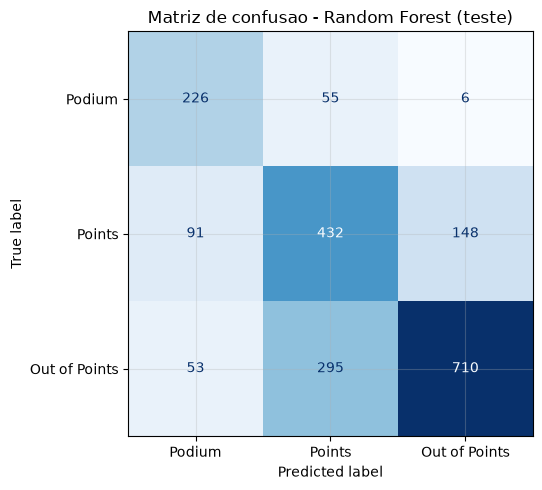

In [38]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_pred, labels=LABELS),
    display_labels=LABELS,
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusao - Random Forest (teste)")
plt.tight_layout()
plt.show()

In [39]:
print("=== Random Forest ===")
print(classification_report(y_test, rf_pred, labels=LABELS, digits=3))
print("=== Regressao Logistica (baseline) ===")
print(classification_report(y_test, lr_pred, labels=LABELS, digits=3))

=== Random Forest ===
               precision    recall  f1-score   support

       Podium      0.611     0.787     0.688       287
       Points      0.552     0.644     0.595       671
Out of Points      0.822     0.671     0.739      1058

     accuracy                          0.679      2016
    macro avg      0.662     0.701     0.674      2016
 weighted avg      0.702     0.679     0.684      2016

=== Regressao Logistica (baseline) ===
               precision    recall  f1-score   support

       Podium      0.529     0.847     0.651       287
       Points      0.565     0.499     0.530       671
Out of Points      0.800     0.729     0.763      1058

     accuracy                          0.669      2016
    macro avg      0.631     0.692     0.648      2016
 weighted avg      0.683     0.669     0.669      2016



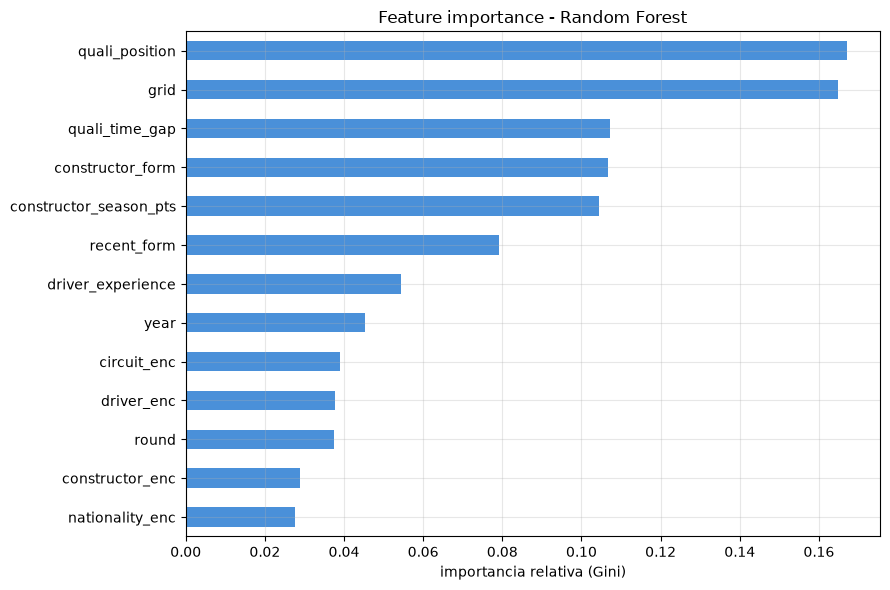

quali_position            0.1671
grid                      0.1647
quali_time_gap            0.1072
constructor_form          0.1067
constructor_season_pts    0.1045
recent_form               0.0791
driver_experience         0.0543
year                      0.0453
circuit_enc               0.0390
driver_enc                0.0378
round                     0.0376
constructor_enc           0.0289
nationality_enc           0.0277
dtype: float64

In [40]:
imp = (pd.Series(rf.feature_importances_, index=FEATURES)
         .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(9, 6))
imp.plot(kind="barh", ax=ax, color="#4a90d9")
ax.set_title("Feature importance - Random Forest")
ax.set_xlabel("importancia relativa (Gini)")
plt.tight_layout()
plt.show()

imp.sort_values(ascending=False).round(4)

### Comentario dos resultados

**Acuracia ~68%**, contra ~52% de um chute sempre na classe majoritaria ("Out of Points") -
ou seja, o modelo agrega valor real. Fica um pouco abaixo da referencia de 70%, o que e esperado:
uma fatia dos erros e ruido irredutivel de corrida (abandonos, safety car).

**O que mais pesa** (feature importance): `grid` e `quali_position` juntas dominam - onde voce
larga explica a maior parte do resultado. Em seguida vem a **forca da equipe**
(`constructor_form` + `constructor_season_pts`) e o `quali_time_gap`. Piloto, circuito e
nacionalidade codificados contribuem pouco isoladamente - grande parte da habilidade do piloto
ja esta "embutida" na posicao de largada e na forma recente.

**Onde o modelo erra mais** (matriz de confusao):
- A classe **"Points" (meio)** e a mais dificil: ela e vizinha das outras duas e e onde caem os
  resultados decididos por detalhes (uma ultrapassagem, um undercut no pit). O modelo troca
  "Points" por "Podium" e por "Out of Points" com frequencia parecida.
- **"Podium"** tem recall alto (acha quase todos os podios reais) mas precision menor: ele preve
  podio as vezes demais para quem larga na frente e acaba caindo para P4-P5.
- **"Out of Points"** e a classe mais solida (precision ~0.8): quem larga la atras num carro fraco
  raramente pontua, e isso o modelo acerta bem.

**Possiveis motivos:** o modelo so conhece o *ponto de partida* da corrida. Ritmo de corrida vs.
ritmo de classificacao, degradacao de pneu, estrategia e incidentes nao estao nas features - e sao
exatamente o que decide as posicoes no meio do pelotao.

## 13. Salvando o modelo com pickle

Guardamos num unico arquivo: o modelo treinado, os encoders (para transformar piloto/equipe/
circuito/nacionalidade novos), a lista de features na ordem certa e as metricas. Assim o modelo
pode ser carregado noutro script (ex.: o app Streamlit) sem repetir todo o pipeline.

In [41]:
bundle = {
    "model": rf,
    "encoders": encoders,
    "features": FEATURES,
    "labels_order": LABELS,
    "classes": list(rf.classes_),
    "params": {"n_form": N_FORM, "grid_back": GRID_BACK, "ano_min": ANO_MIN},
    "metrics": {"rf_accuracy": float(rf_acc), "logreg_accuracy": float(lr_acc),
                "cv_mean": float(cv.mean())},
}

with open("f1_model.pkl", "wb") as fh:
    pickle.dump(bundle, fh)

# conferindo que da para recarregar e prever
with open("f1_model.pkl", "rb") as fh:
    loaded = pickle.load(fh)
print("modelo recarregado. Features:", len(loaded["features"]))
print("previsao de exemplo:", loaded["model"].predict(X_test.head(3)).tolist())

modelo recarregado. Features: 13
previsao de exemplo: ['Out of Points', 'Points', 'Points']


## 14. Conclusoes

**O que foi feito.** Um pipeline completo que, a partir de 7 tabelas do dataset historico da F1,
constroi um classificador de 3 classes (Podium / Points / Out of Points) para cada piloto **antes**
da corrida. Era moderna (2000-2024), ~10 mil linhas piloto-corrida.

**Resultado.** Random Forest com **~68% de acuracia** no teste (vs. ~52% do baseline trivial e
~67% da Regressao Logistica). Validacao cruzada confirma que o numero e estavel.

**Principais aprendizados:**
- **Largada manda.** `grid` + `quali_position` sao de longe as features mais importantes.
- **Equipe > piloto** nas features: a forca do carro pesa mais que o piloto codificado, porque a
  habilidade do piloto ja vaza para a posicao de largada e a forma recente.
- **O meio do grid e caotico.** A classe "Points" concentra os erros - e onde a corrida (nao a
  largada) decide.
- **Modelo simples chega perto.** A pequena vantagem do RF sobre a regressao logistica mostra que
  o problema e majoritariamente linear.

**Limitacoes (o que o modelo NAO ve):** clima da corrida, safety car, batidas, estrategia de pit
stop, ritmo de corrida vs. de classificacao, ordens de equipe, penalidades aplicadas durante a prova.

**Melhorias futuras:**
- dados de **clima** por corrida (chuva embaralha tudo);
- **tempos de volta** de classificacao e de treino livre como proxy de ritmo puro;
- testar **XGBoost / LightGBM** (gradient boosting costuma ganhar alguns pontos aqui);
- feature de **historico do piloto naquele circuito especifico**;
- **split temporal** e re-treino incremental para simular uso em producao;
- calibrar probabilidades e entregar "chance de podio: 62%" em vez de so a classe.